In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error

pd.set_option("display.max_columns", 30)
plt.style.use("seaborn-v0_8-whitegrid")

In [2]:
DATA = Path("../data/processed/south_africa_svir_inputs.csv")
df = pd.read_csv(DATA, parse_dates=["date"]).sort_values("date").reset_index(drop=True)

N = float(df["N"].iloc[0])
mu = 9.5 / 1000 / 365
pi = mu * N

params = {
    "pi": pi, "mu": mu, "omega": 0.001, "sigma": 1/180,
    "epsilon": 0.65, "gamma": 1/5, "rho1": 1/10, "rho2": 1/12,
    "delta": 0.001, "beta": 0.106, "N": N,   # β from earlier fit
}

y0 = [df["S"].iloc[0], df["V"].iloc[0], df["I"].iloc[0],
      df["Ic"].iloc[0], df["R"].iloc[0]]

def svir_ode(t, y, p, omega_func=None):
    S, V, I, Ic, R = y
    N = p["N"]
    beta, epsilon = p["beta"], p["epsilon"]
    gamma, rho1, rho2 = p["gamma"], p["rho1"], p["rho2"]
    delta, sigma, mu, pi = p["delta"], p["sigma"], p["mu"], p["pi"]
    omega = omega_func(t) if omega_func is not None else p["omega"]
    lam = beta * (I + Ic) / N
    dS  = pi + sigma*V - lam*S - omega*S - mu*S
    dV  = omega*S - (1-epsilon)*lam*V - sigma*V - mu*V
    dI  = lam*S + (1-epsilon)*lam*V - (mu+gamma+rho1+delta)*I
    dIc = gamma*I - (mu+rho2+delta)*Ic
    dR  = rho1*I + rho2*Ic - mu*R
    return [dS, dV, dI, dIc, dR]

print("Loaded", len(df), "days | N =", f"{N:,.0f}")


Loaded 525 days | N = 59,893,884


In [4]:
t_eval = np.arange(len(df))
t_span = (0, len(df)-1)

omega_interp = interp1d(t_eval, df["omega_proxy"].values,
                        bounds_error=False,
                        fill_value=(df["omega_proxy"].iloc[0], df["omega_proxy"].iloc[-1]))

def omega_func(t):
    return float(omega_interp(np.clip(t, 0, len(df)-1)))

sol = solve_ivp(
    fun=lambda t, y: svir_ode(t, y, params, omega_func),
    t_span=t_span, y0=y0, t_eval=t_eval,
    method="RK45", rtol=1e-6, atol=1e-8
)
assert sol.success

sim = pd.DataFrame({
    "date": df["date"],
    "y_obs": df["y_daily_confirmed"].values,
    "y_mech": params["gamma"] * sol.y[2],
})
sim["residual"] = sim["y_obs"] - sim["y_mech"]
print("Mechanistic MAE:", round(mean_absolute_error(sim["y_obs"], sim["y_mech"]), 0))


Mechanistic MAE: 4289.0


In [6]:
sim["t_norm"] = np.arange(len(sim)) / (len(sim)-1)
sim["vax_coverage"] = df["full_vax_coverage"].values
sim["month"] = sim["date"].dt.month
sim["dow"] = sim["date"].dt.dayofweek

for lag in [1, 7, 14]:
    sim[f"resid_lag{lag}"] = sim["residual"].shift(lag)

sim_model = sim.dropna().reset_index(drop=True)

feature_cols = ["t_norm", "vax_coverage", "month", "dow",
                "resid_lag1", "resid_lag7", "resid_lag14"]

X = sim_model[feature_cols]
y = sim_model["residual"]

residual_model = HistGradientBoostingRegressor(
    max_iter=150, max_depth=3, learning_rate=0.05,
    min_samples_leaf=20, random_state=42
)
residual_model.fit(X, y)

sim_model["residual_hat"] = residual_model.predict(X)
sim_model["y_hybrid"] = sim_model["y_mech"] + sim_model["residual_hat"]

print("In-sample hybrid MAE:", round(mean_absolute_error(sim_model["y_obs"], sim_model["y_hybrid"]), 0))


In-sample hybrid MAE: 703.0


In [9]:
def forecast(horizon=14, last_known_date=None):
    """Produce a hybrid forecast for the next `horizon` days.
    Uses the last observed residual lags and assumes vaccination coverage
    stays at its last value (simple baseline).
    """
    if last_known_date is None:
        last_known_date = sim_model["date"].max()

    hist = sim_model[sim_model["date"] <= last_known_date].copy()
    if len(hist) < 14:
        raise ValueError("Need at least 14 days of history for lags")

    future_dates = pd.date_range(hist["date"].iloc[-1] + pd.Timedelta(days=1),
                                 periods=horizon, freq="D")

    # Mechanistic continuation (constant last ω, same β)
    t0 = len(df[df["date"] <= last_known_date]) - 1
    t_future = np.arange(t0, t0 + horizon + 1)
    y_last = [sol.y[i, t0] for i in range(5)]

    def omega_future(t):
        return float(df["omega_proxy"].iloc[min(int(t), len(df)-1)])

    sol_f = solve_ivp(
        fun=lambda t, y: svir_ode(t, y, params, omega_future),
        t_span=(t0, t0 + horizon),
        y0=y_last,
        t_eval=t_future,
        method="RK45", rtol=1e-6, atol=1e-8
    )
    y_mech_f = params["gamma"] * sol_f.y[2, 1:]   # drop the starting point

    # Build future feature rows (lags decay / held constant after first step)
    last_resid = hist["residual"].iloc[-14:].values
    rows = []
    for i, d in enumerate(future_dates):
        t_norm = (t0 + 1 + i) / (len(df) - 1)
        vax = hist["vax_coverage"].iloc[-1]
        month, dow = d.month, d.dayofweek
        # simple lag handling: use last known residuals, then predicted ones
        r1 = last_resid[-1] if i == 0 else rows[-1]["resid_lag1"]
        r7 = last_resid[-7] if i < 7 else rows[i-7]["resid_lag1"]
        r14 = last_resid[-14] if i < 14 else rows[i-14]["resid_lag1"]
        rows.append({
            "date": d, "t_norm": t_norm, "vax_coverage": vax,
            "month": month, "dow": dow,
            "resid_lag1": r1, "resid_lag7": r7, "resid_lag14": r14,
            "y_mech": y_mech_f[i]
        })

    fut = pd.DataFrame(rows)
    fut["residual_hat"] = residual_model.predict(fut[feature_cols])
    fut["y_hybrid"] = fut["y_mech"] + fut["residual_hat"]
    return fut[["date", "y_mech", "residual_hat", "y_hybrid"]]

# Example: 14-day forecast from the end of the series
fc = forecast(horizon=90)
print(fc.round(1))


         date  y_mech  residual_hat  y_hybrid
0  2022-07-26  5922.0       -4784.2    1137.8
1  2022-07-27  5945.4       -4802.0    1143.3
2  2022-07-28  5969.0       -5097.0     871.9
3  2022-07-29  5992.7       -5140.1     852.7
4  2022-07-30  6016.6       -5157.8     858.9
..        ...     ...           ...       ...
85 2022-10-19  8436.8       -4882.9    3553.8
86 2022-10-20  8471.8       -5177.9    3293.8
87 2022-10-21  8506.8       -5221.0    3285.9
88 2022-10-22  8542.0       -5238.7    3303.3
89 2022-10-23  8577.3       -5524.7    3052.5

[90 rows x 4 columns]


C:\Users\shadr\AppData\Local\Temp\ipykernel_3372\964489014.py:58: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(fc.round(1))


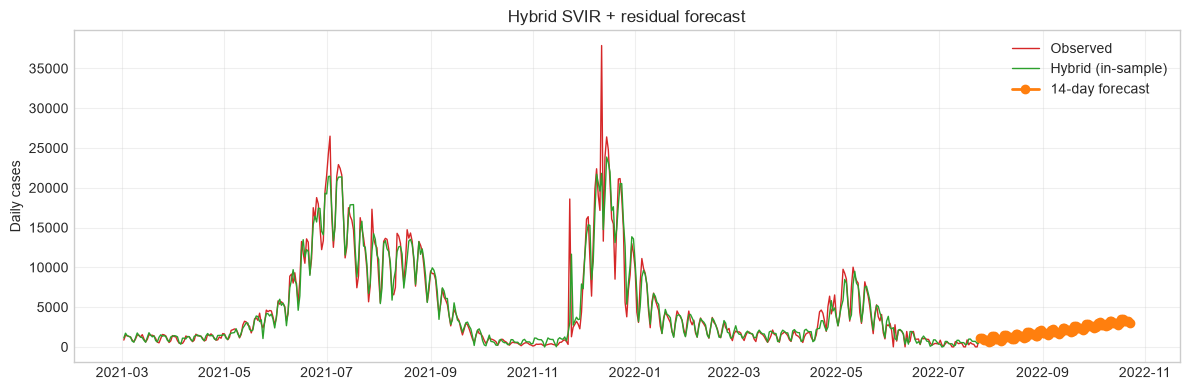

In [10]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(sim_model["date"], sim_model["y_obs"], label="Observed", color="tab:red", lw=1)
ax.plot(sim_model["date"], sim_model["y_hybrid"], label="Hybrid (in-sample)", color="tab:green", lw=1)
ax.plot(fc["date"], fc["y_hybrid"], label="14-day forecast", color="tab:orange", lw=2, marker="o")
ax.set_ylabel("Daily cases")
ax.legend()
ax.set_title("Hybrid SVIR + residual forecast")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
